<a href="https://colab.research.google.com/github/HinnaNayab/DeepLearning/blob/Applied-AI/Tutorial_11_Semantic_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import glob
import os
import torch
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
#Loading Pretrained DeepLabV3 with ResNet-101 backbone
deeplab = models.segmentation.deeplabv3_resnet101(weights="DEFAULT").to(device)
deeplab.eval()

#Pascal VOC 21 Class Names & Color Palette
VOC_CLASSES = [
    "Background", "Aeroplane", "Bicycle", "Bird", "Boat",
    "Bottle", "Bus", "Car", "Cat", "Chair",
    "Cow", "Dining Table", "Dog", "Horse", "Motorbike",
    "Person", "Potted Plant", "Sheep", "Sofa", "Train", "TV/Monitor"
]

def decode_segmentation(mask, num_classes=21):
    colors = np.array([
        [0, 0, 0], [128, 0, 0], [0, 128, 0], [128, 128, 0],
        [0, 0, 128], [128, 0, 128], [0, 128, 128], [128, 128, 128],
        [64, 0, 0], [192, 0, 0], [64, 128, 0], [192, 128, 0],
        [64, 0, 128], [192, 0, 128], [64, 128, 128], [192, 128, 128],
        [0, 64, 0], [128, 64, 0], [0, 192, 0], [128, 192, 0],
        [0, 64, 128]
    ])
    r = np.zeros_like(mask, dtype=np.uint8)
    g = np.zeros_like(mask, dtype=np.uint8)
    b = np.zeros_like(mask, dtype=np.uint8)
    for cls in range(num_classes):
        idx = (mask == cls)
        r[idx] = colors[cls, 0]
        g[idx] = colors[cls, 1]
        b[idx] = colors[cls, 2]
    return np.stack([r, g, b], axis=2)

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet101_coco-586e9e4e.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet101_coco-586e9e4e.pth


100%|██████████| 233M/233M [00:01<00:00, 174MB/s]


Found zip file: /content/polarbearsdata.zip. Extracting...
Extraction complete!
Directory contents of /content: ['.config', 'polarbearsdata.zip', 'labels-COCO-JSON.json', 'polarbearsdata', 'sample_data']
Found 146 image(s). Example path: /content/polarbearsdata/44fdf1aa5c54b2dcfcb48a047f2672d9215297d7.jpeg
Classes predicted by Pretrained DeepLabV3: ['Background', 'Cat', 'Dog', 'Sheep']


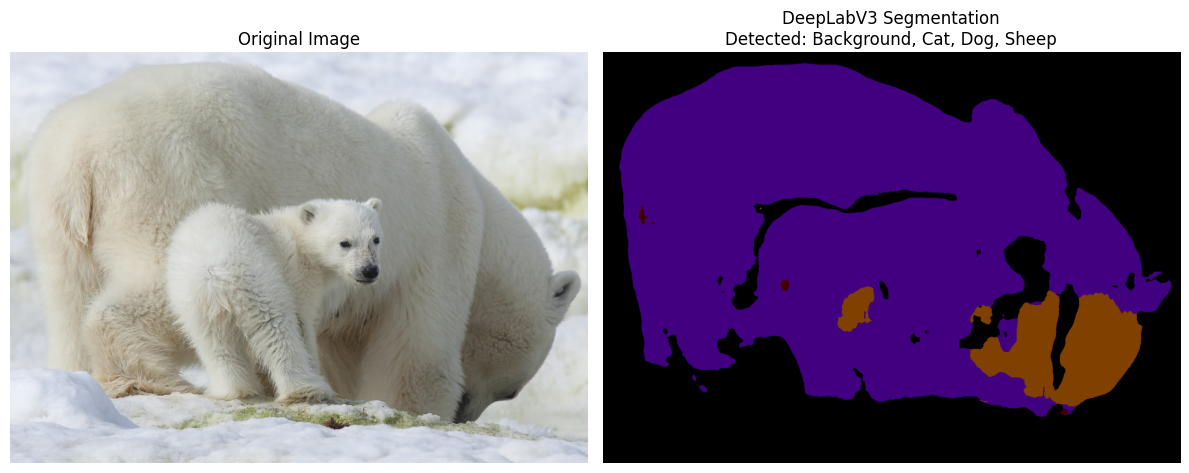

In [4]:
# 3. Preprocessing Pipeline
import zipfile
import os
import glob

# Let's find any zip file in /content
zips = glob.glob("/content/*.zip")
if zips:
    zip_path = zips[0]
    print(f"Found zip file: {zip_path}. Extracting...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/")
    print("Extraction complete!")
else:
    print("No .zip file found in /content/")

# List the directory contents to debug
print("Directory contents of /content:", os.listdir("/content"))

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Search broadly for any image file inside /content/ to find the correct path
all_imgs = sorted([
    p for p in glob.glob("/content/**/*.*", recursive=True)
    if p.lower().endswith((".jpg", ".jpeg", ".png")) and "/masks/" not in p and "sample_data" not in p
])

if len(all_imgs) == 0:
    raise RuntimeError("No images found. Please verify that the dataset was unzipped successfully and contains images.")

print(f"Found {len(all_imgs)} image(s). Example path: {all_imgs[0]}")
sample_image_path = all_imgs[0]
image = Image.open(sample_image_path).convert("RGB")
input_tensor = preprocess(image).unsqueeze(0).to(device)

#Performing Multi-Class Semantic Segmentation
with torch.no_grad():
    output = deeplab(input_tensor)["out"][0]
    output_predictions = output.argmax(0).cpu().numpy()

detected_ids = np.unique(output_predictions)
detected_names = [VOC_CLASSES[i] for i in detected_ids if i < len(VOC_CLASSES)]
print(f"Classes predicted by Pretrained DeepLabV3: {detected_names}")

segmentation_map = decode_segmentation(output_predictions)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1); plt.title("Original Image"); plt.imshow(image); plt.axis("off")
plt.subplot(1, 2, 2); plt.title(f"DeepLabV3 Segmentation\nDetected: {', '.join(detected_names)}"); plt.imshow(segmentation_map); plt.axis("off")
plt.tight_layout()
plt.show()

PASCAL VOC doesn't have a bear class, hence the 'Background', 'Cat', 'Dog', 'Sheep' predictions lol

Dataset initialized. Train samples: 116, Val samples: 30
Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 119MB/s]


Fine-Tuned DeepLabV3 Epoch 1/8 | Loss: 0.4813
Fine-Tuned DeepLabV3 Epoch 2/8 | Loss: 0.2860
Fine-Tuned DeepLabV3 Epoch 3/8 | Loss: 0.1749
Fine-Tuned DeepLabV3 Epoch 4/8 | Loss: 0.1284
Fine-Tuned DeepLabV3 Epoch 5/8 | Loss: 0.1054
Fine-Tuned DeepLabV3 Epoch 6/8 | Loss: 0.0910
Fine-Tuned DeepLabV3 Epoch 7/8 | Loss: 0.0726
Fine-Tuned DeepLabV3 Epoch 8/8 | Loss: 0.0606


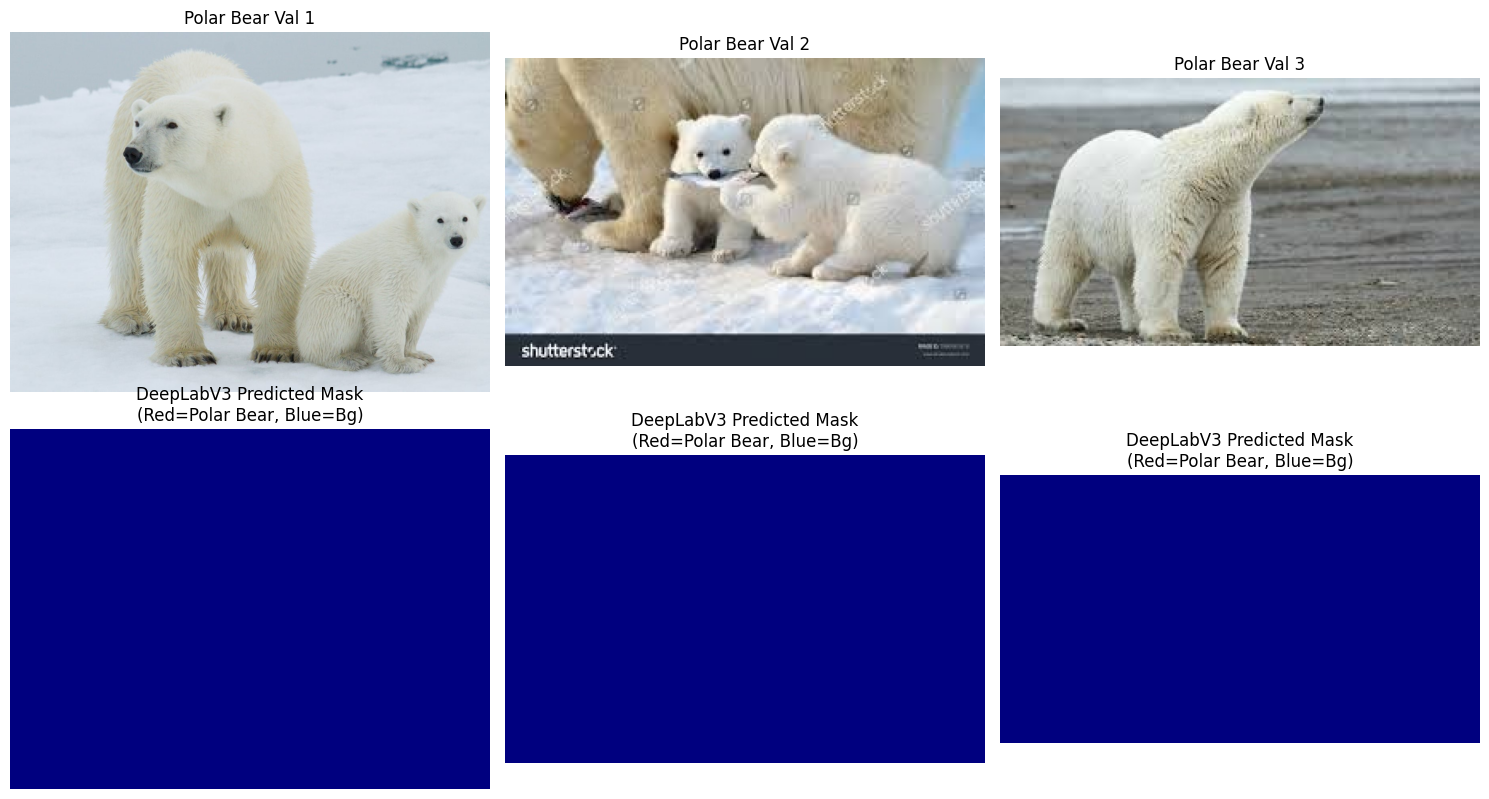

In [5]:
import cv2
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Dataset Loader for Semantic Segmentation (Dynamically split flat directory into train/val)
class PolarBearSemanticDataset(Dataset):
    def __init__(self, split, img_size=256, split_ratio=0.8):
        # Find all images in the folder
        all_img_paths = sorted([
            p for p in glob.glob("/content/polarbearsdata/**/*.*", recursive=True)
            if p.lower().endswith((".jpg", ".jpeg", ".png")) and "/masks/" not in p
        ])

        # Consistent random split
        np.random.seed(42)
        indices = np.random.permutation(len(all_img_paths))
        split_idx = int(len(all_img_paths) * split_ratio)

        if split == "train":
            self.img_paths = [all_img_paths[i] for i in indices[:split_idx]]
        else:
            self.img_paths = [all_img_paths[i] for i in indices[split_idx:]]

        self.split = split
        self.img_size = img_size

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        p = self.img_paths[idx]
        base = os.path.splitext(os.path.basename(p))[0]
        # Locate mask regardless of subdirectory depth
        mask_search = glob.glob(f"/content/polarbearsdata/**/masks/{base}.png", recursive=True)
        if mask_search:
            mp = mask_search[0]
        else:
            # fallback to direct path
            mp = f"/content/polarbearsdata/masks/{base}.png"

        im = cv2.resize(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB), (self.img_size, self.img_size))
        img_t = preprocess(Image.fromarray(im))

        # Handle missing masks gracefully
        if os.path.exists(mp):
            mk = (cv2.resize(cv2.imread(mp, 0), (self.img_size, self.img_size)) > 127).astype(np.int64)
        else:
            mk = np.zeros((self.img_size, self.img_size), dtype=np.int64)

        return img_t, torch.tensor(mk, dtype=torch.long)

train_sem_dataset = PolarBearSemanticDataset("train")
val_sem_dataset = PolarBearSemanticDataset("val")

train_sem_loader = DataLoader(train_sem_dataset, batch_size=4, shuffle=True, drop_last=True)

print(f"Dataset initialized. Train samples: {len(train_sem_dataset)}, Val samples: {len(val_sem_dataset)}")

# 2. Adapt Pretrained DeepLabV3-ResNet50 for Custom Polar Bear Segmentation
custom_deeplab = models.segmentation.deeplabv3_resnet50(weights="DEFAULT")
custom_deeplab.classifier[4] = nn.Conv2d(256, 2, kernel_size=1) # 0 = Background, 1 = Polar Bear
custom_deeplab.to(device)

optimizer = torch.optim.AdamW(custom_deeplab.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

for epoch in range(8):
    custom_deeplab.train()
    ep_loss = 0.0
    for imgs, masks in train_sem_loader:
        imgs, masks = imgs.to(device), masks.to(device)
        optimizer.zero_grad()
        out = custom_deeplab(imgs)["out"]
        loss = criterion(out, masks)
        loss.backward()
        optimizer.step()
        ep_loss += loss.item()
    print(f"Fine-Tuned DeepLabV3 Epoch {epoch+1}/8 | Loss: {ep_loss/len(train_sem_loader):.4f}")

# 3. Test & Visualize on Validation Polar Bears
custom_deeplab.eval()
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i in range(min(3, len(val_sem_dataset))):
    img_path = val_sem_dataset.img_paths[i]
    orig_img = Image.open(img_path).convert("RGB")
    inp = preprocess(orig_img).unsqueeze(0).to(device)

    with torch.no_grad():
        pred_mask = custom_deeplab(inp)["out"][0].argmax(0).cpu().numpy()

    axes[0, i].imshow(orig_img); axes[0, i].set_title(f"Polar Bear Val {i+1}"); axes[0, i].axis("off")
    axes[1, i].imshow(pred_mask, cmap="jet"); axes[1, i].set_title("DeepLabV3 Predicted Mask\n(Red=Polar Bear, Blue=Bg)"); axes[1, i].axis("off")

plt.tight_layout()
plt.show()

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:00<00:00, 179MB/s]


Mask R-CNN Epoch 1/6 | Loss: 0.3995
Mask R-CNN Epoch 2/6 | Loss: 0.1299
Mask R-CNN Epoch 3/6 | Loss: 0.1009
Mask R-CNN Epoch 4/6 | Loss: 0.0821
Mask R-CNN Epoch 5/6 | Loss: 0.0699
Mask R-CNN Epoch 6/6 | Loss: 0.0609


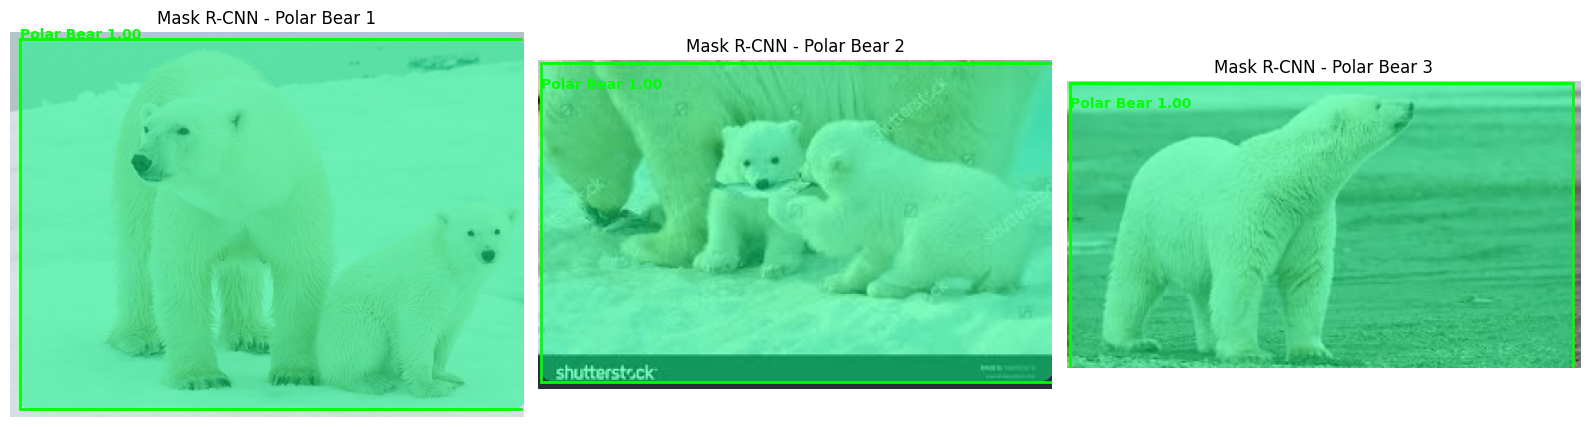

In [6]:
#implementing Mask-RCNN

import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
import matplotlib.patches as patches

# 1. Load Pretrained Mask R-CNN (ResNet50-FPN) & Adapt Heads for Polar Bears
mask_rcnn = torchvision.models.detection.maskrcnn_resnet50_fpn(weights="DEFAULT")

# Replace Box Predictor (0=Background, 1=Polar Bear)
in_features_box = mask_rcnn.roi_heads.box_predictor.cls_score.in_features
mask_rcnn.roi_heads.box_predictor = FastRCNNPredictor(in_features_box, num_classes=2)

# Replace Mask Predictor
in_features_mask = mask_rcnn.roi_heads.mask_predictor.conv5_mask.in_channels
mask_rcnn.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask, dim_reduced=256, num_classes=2)
mask_rcnn.to(device)

# 2. Dataset Loader Returning Image + Bounding Boxes + Instance Binary Masks
class PolarBearMaskRCNNDataset(Dataset):
    def __init__(self, split, split_ratio=0.8):
        # Find all images in the folder
        all_img_paths = sorted([
            p for p in glob.glob("/content/polarbearsdata/**/*.*", recursive=True)
            if p.lower().endswith((".jpg", ".jpeg", ".png")) and "/masks/" not in p
        ])

        # Consistent random split
        np.random.seed(42)
        indices = np.random.permutation(len(all_img_paths))
        split_idx = int(len(all_img_paths) * split_ratio)

        if split == "train":
            self.img_paths = [all_img_paths[i] for i in indices[:split_idx]]
        else:
            self.img_paths = [all_img_paths[i] for i in indices[split_idx:]]

        self.split = split

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        p = self.img_paths[idx]
        img = Image.open(p).convert("RGB")
        w, h = img.size
        img_t = transforms.ToTensor()(img)

        base = os.path.splitext(os.path.basename(p))[0]
        # Locate mask regardless of subdirectory depth
        mask_search = glob.glob(f"/content/polarbearsdata/**/masks/{base}.png", recursive=True)
        if mask_search:
            mp = mask_search[0]
        else:
            mp = f"/content/polarbearsdata/masks/{base}.png"

        if os.path.exists(mp):
            full_mask = (cv2.imread(mp, 0) > 127).astype(np.uint8)
        else:
            full_mask = np.zeros((h, w), dtype=np.uint8)

        # Extract connected components so each bear gets its own box & instance mask
        num_labels, labels_im, stats, _ = cv2.connectedComponentsWithStats(full_mask)
        boxes, masks = [], []
        for lbl in range(1, num_labels):
            x, y, bw, bh, area = stats[lbl]
            if area > 100 and bw > 5 and bh > 5:
                boxes.append([float(x), float(y), float(x + bw), float(y + bh)])
                masks.append((labels_im == lbl).astype(np.uint8))

        if len(boxes) == 0:
            boxes = [[0.0, 0.0, float(w), float(h)]]
            masks = [np.ones((h, w), dtype=np.uint8)]

        target = {
            "boxes": torch.tensor(boxes, dtype=torch.float32),
            "labels": torch.ones((len(boxes),), dtype=torch.int64),
            "masks": torch.tensor(np.array(masks), dtype=torch.uint8)
        }
        return img_t, target

mrcnn_dataset_train = PolarBearMaskRCNNDataset("train")
mrcnn_dataset_val = PolarBearMaskRCNNDataset("val")
mrcnn_loader = DataLoader(mrcnn_dataset_train, batch_size=2, shuffle=True, collate_fn=lambda b: tuple(zip(*b)))

# 3. Train Mask R-CNN on Polar Bear Dataset
optimizer_mrcnn = torch.optim.AdamW(mask_rcnn.parameters(), lr=1e-4, weight_decay=1e-4)

for epoch in range(6):
    mask_rcnn.train()
    ep_loss = 0.0
    for imgs, targets in mrcnn_loader:
        imgs = [im.to(device) for im in imgs]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = mask_rcnn(imgs, targets)
        loss = sum(l for l in loss_dict.values())
        optimizer_mrcnn.zero_grad()
        loss.backward()
        optimizer_mrcnn.step()
        ep_loss += loss.item()
    print(f"Mask R-CNN Epoch {epoch+1}/6 | Loss: {ep_loss/len(mrcnn_loader):.4f}")

# 4. Visualize Mask R-CNN Instance Segmentation (Box + Label + Colored Mask)
mask_rcnn.eval()
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i in range(min(3, len(mrcnn_dataset_val))):
    p = mrcnn_dataset_val.img_paths[i]
    pil_img = Image.open(p).convert("RGB")
    img_np = np.array(pil_img)
    img_t = transforms.ToTensor()(pil_img).to(device)

    with torch.no_grad():
        pred = mask_rcnn([img_t])[0]

    overlay = img_np.copy()
    axes[i].imshow(overlay)
    axes[i].set_title(f"Mask R-CNN - Polar Bear {i+1}")
    axes[i].axis("off")

    for box, score, mask in zip(pred["boxes"].cpu(), pred["scores"].cpu(), pred["masks"].cpu()):
        if score > 0.5:
            x1, y1, x2, y2 = box.tolist()
            binary_m = (mask[0].numpy() > 0.5)
            overlay[binary_m] = (overlay[binary_m] * 0.5 + np.array([0, 255, 128]) * 0.5).astype(np.uint8)
            axes[i].imshow(overlay)
            rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor="lime", facecolor="none")
            axes[i].add_patch(rect)
            axes[i].text(x1, max(15, y1 - 6), f"Polar Bear {score:.2f}", color="lime", fontweight="bold")

plt.tight_layout()
plt.show()